# Demonstração: algoritmo genético para o VRP de entrega de medicamentos

Este notebook roda o algoritmo genético do projeto (**open VRP**: vários veículos, rotas abertas e origem fixa em São Paulo) sobre as 16 cidades do dataset fixo `backend/data/route_cities.py`, e mostra:

1. a melhor solução encontrada, com a rota de cada veículo;
2. a evolução da distância ao longo das gerações;
3. as rotas desenhadas, uma cor por veículo;
4. a comparação entre as três estratégias de população inicial;
5. o efeito do número de veículos.

**Sem custo e sem rede:** a matriz de distâncias e durações (OpenRouteService) foi calculada uma única vez e está em `backend/data/demo_routes.json`. Este notebook não chama o OpenRouteService nem a LLM (OpenAI). Todas as execuções usam semente fixa, então os resultados são reproduzíveis.

Para rodar: a partir da raiz do projeto, com o ambiente virtual ativo, `pip install -r backend/requirements.txt` e `jupyter lab notebooks/demo.ipynb` (ou abra no VS Code).

In [1]:
import sys
from pathlib import Path

# O notebook fica em notebooks/; o pacote `backend` está na raiz do projeto.
root = Path.cwd().resolve()
root = root.parent if root.name == "notebooks" else root
sys.path.insert(0, str(root))

import matplotlib.pyplot as plt

from backend.demo import format_summary, run_demo, vehicle_summaries, format_duration
from backend.data import sao_paulo_cities

plt.rcParams["figure.dpi"] = 110
VEHICLE_COLORS = ["#1f4e9c", "#e07b00", "#2e8b57", "#b03a8c", "#6b6b6b"]

## 1. Cidades

São 16 cidades do estado de São Paulo. A origem (`id == 0`, São Paulo) é a primeira cidade de todas as rotas, e as cidades marcadas como prioritárias precisam ser atendidas em até 17 h.

In [2]:
for city in sao_paulo_cities:
    marks = []
    if city["id"] == 0:
        marks.append("origem")
    if city["priority"]:
        marks.append("PRIORIDADE")
    print(f"{city['id']:>2}  {city['name']:<22} {', '.join(marks)}")

 0  São Paulo              origem
 1  Araçatuba              
 2  Assis                  
 3  Barretos               
 4  Bauru                  
 5  Bragança Paulista      
 6  Campinas               PRIORIDADE
 7  Caraguatatuba          PRIORIDADE
 8  Franca                 
 9  Guaratinguetá          
10  Itapeva                
11  Jales                  
12  Marília                
13  Ribeirão Preto         PRIORIDADE
14  São Carlos             
15  Taubaté                


## 2. Melhor solução (3 veículos)

Parâmetros: população inicial por vizinho mais próximo, população de 200, probabilidade de mutação 0,5 e parada com 500 gerações ou 100 sem melhora (valores reduzidos em relação ao app web para a demonstração terminar em segundos).

In [3]:
result = run_demo(strategy="nearest_neighbor", vehicles_number=3, seed=42)
print(format_summary(result))

Estratégia: nearest_neighbor | veículos: 3 | população: 200 | semente: 42
Gerações: 124 (1.0s)

Veículo 1 — 541.7 km, 8h58min
  São Paulo → Campinas → Bragança Paulista → Guaratinguetá → Taubaté → Caraguatatuba
Veículo 2 — 812.9 km, 11h59min
  São Paulo → Bauru → São Carlos → Ribeirão Preto → Franca → Barretos
Veículo 3 — 971.3 km, 15h03min
  São Paulo → Itapeva → Assis → Marília → Araçatuba → Jales

Distância total: 2325.8 km
Duração da solução (veículo mais demorado): 15h03min
Prioridades dentro do prazo: sim


## 3. Evolução da distância por geração

A curva mostra a distância total (soma de todos os veículos) da melhor solução de cada geração. O elitismo garante que ela nunca piora.

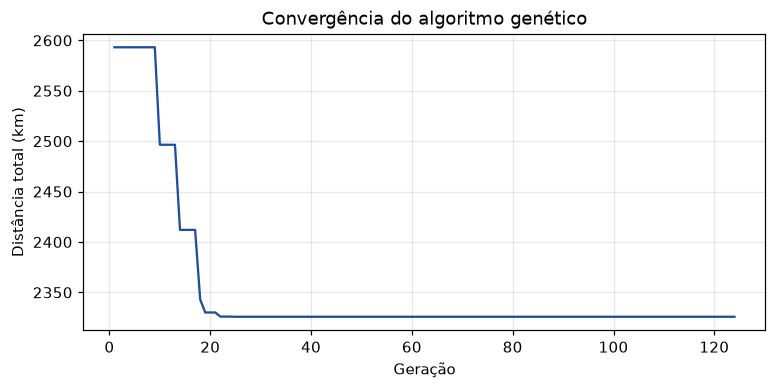

Primeira geração: 2593.2 km -> última: 2325.8 km (redução de 10.3%)


In [4]:
history = result["fitness_history"]

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(range(1, len(history) + 1), history, color=VEHICLE_COLORS[0])
ax.set_xlabel("Geração")
ax.set_ylabel("Distância total (km)")
ax.set_title("Convergência do algoritmo genético")
ax.grid(alpha=0.3)
plt.show()

print(f"Primeira geração: {history[0]:.1f} km -> última: {history[-1]:.1f} km "
      f"(redução de {(1 - history[-1] / history[0]) * 100:.1f}%)")

## 4. Rotas no mapa

Cada cor é um veículo. As rotas são **abertas**: o veículo não volta para São Paulo. A estrela marca a origem e os círculos vermelhos, as cidades prioritárias. As linhas ligam as cidades em linha reta (as distâncias usadas pelo algoritmo são rodoviárias, vindas do OpenRouteService).

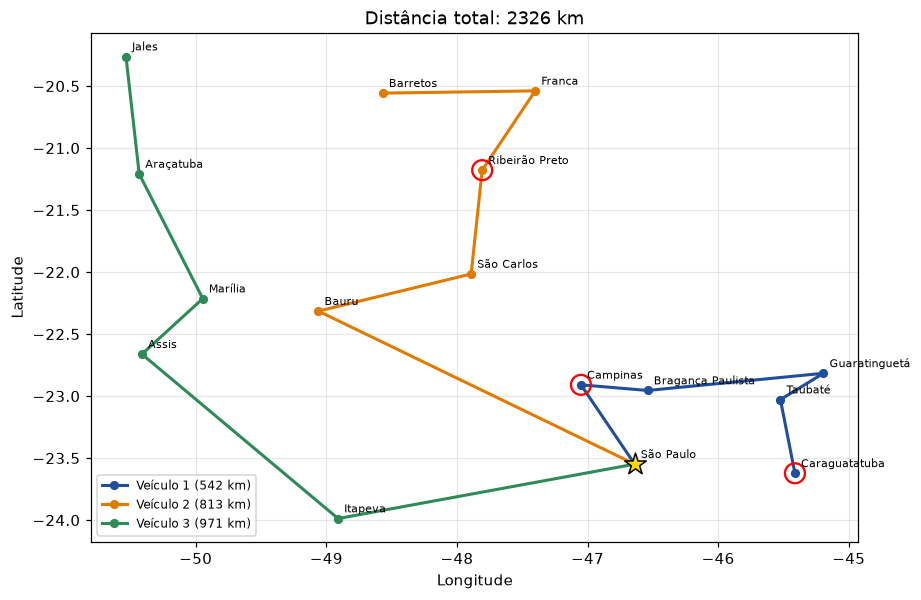

In [5]:
coordinates = {
    city["name"]: (float(city["coordinates"][0]), float(city["coordinates"][1]))
    for city in sao_paulo_cities
}
priority_names = {city["name"] for city in sao_paulo_cities if city["priority"]}


def plot_routes(result, ax, title=None):
    for index, vehicle in enumerate(vehicle_summaries(result)):
        longitudes = [coordinates[name][0] for name in vehicle["route"]]
        latitudes = [coordinates[name][1] for name in vehicle["route"]]
        ax.plot(longitudes, latitudes, "-o", color=VEHICLE_COLORS[index % len(VEHICLE_COLORS)],
                linewidth=2, markersize=5, label=f"Veículo {index + 1} ({vehicle['distance_km']:.0f} km)")

    for name, (longitude, latitude) in coordinates.items():
        if name in priority_names:
            ax.scatter(longitude, latitude, s=170, facecolors="none", edgecolors="red", linewidths=1.5, zorder=3)
        ax.annotate(name, (longitude, latitude), fontsize=7, xytext=(4, 4), textcoords="offset points")

    origin_longitude, origin_latitude = coordinates["São Paulo"]
    ax.scatter(origin_longitude, origin_latitude, marker="*", s=220, color="gold", edgecolors="black", zorder=4)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_title(title or f"Distância total: {result['best_solution']['total_distance']:.0f} km")
    ax.legend(loc="lower left", fontsize=8)
    ax.grid(alpha=0.3)


fig, ax = plt.subplots(figsize=(9, 6))
plot_routes(result, ax)
plt.show()

## 5. Estratégias de população inicial

As três estratégias (`random`, `nearest_neighbor` e `cheapest_insertion`) são executadas com 5 sementes diferentes cada, nos mesmos parâmetros. Como o algoritmo é estocástico, a média e o melhor resultado entre as sementes dão uma comparação mais justa do que uma execução só.

In [6]:
import statistics

STRATEGIES = ["random", "nearest_neighbor", "cheapest_insertion"]
SEEDS = [1, 2, 3, 4, 5]

runs_by_strategy = {
    strategy: [run_demo(strategy=strategy, vehicles_number=3, seed=seed) for seed in SEEDS]
    for strategy in STRATEGIES
}

print(f"{'Estratégia':<20}{'Distância média':>16}{'Melhor':>10}{'Pior':>10}{'Gerações (média)':>18}{'Válidas':>9}")
for strategy, runs in runs_by_strategy.items():
    distances = [run["best_solution"]["total_distance"] for run in runs]
    generations = [len(run["fitness_history"]) for run in runs]
    valid = sum(run["best_solution"]["priorities_on_time"] for run in runs)
    print(f"{strategy:<20}{statistics.mean(distances):>13.1f} km{min(distances):>7.1f} km{max(distances):>7.1f} km"
          f"{statistics.mean(generations):>18.0f}{valid:>6}/{len(runs)}")

Estratégia           Distância média    Melhor      Pior  Gerações (média)  Válidas
random                     2339.9 km 2325.8 km 2360.8 km               142     5/5
nearest_neighbor           2328.3 km 2325.8 km 2338.3 km               131     5/5
cheapest_insertion         2404.7 km 2325.8 km 2672.3 km               138     5/5


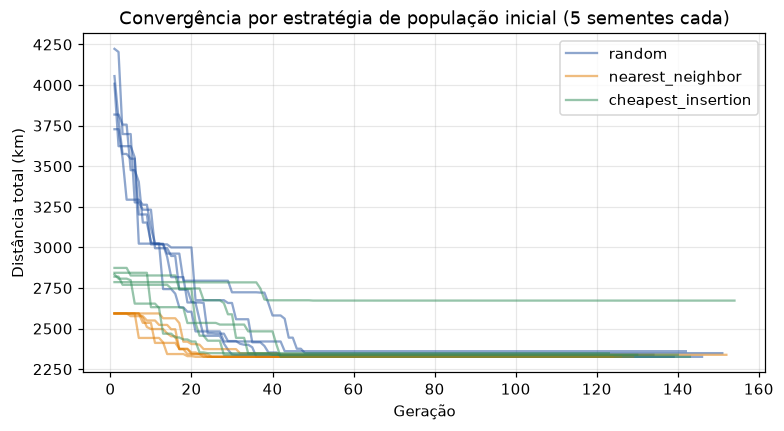

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
for color, (strategy, runs) in zip(VEHICLE_COLORS, runs_by_strategy.items()):
    for index, run in enumerate(runs):
        ax.plot(range(1, len(run["fitness_history"]) + 1), run["fitness_history"],
                color=color, alpha=0.5, label=strategy if index == 0 else None)
ax.set_xlabel("Geração")
ax.set_ylabel("Distância total (km)")
ax.set_title("Convergência por estratégia de população inicial (5 sementes cada)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 6. Efeito do número de veículos

O que muda com mais veículos: cada rota sai de São Paulo, o que tende a somar quilômetros, mas as cidades são divididas entre mais motoristas, e a duração da solução (a do veículo mais demorado) cai. Todas as execuções abaixo usam a mesma semente.

In [8]:
print(f"{'Veículos':<10}{'Distância total':>16}{'Duração (mais demorado)':>26}{'Prioridades no prazo':>22}")
vehicle_runs = {}
for vehicles in [1, 2, 3, 4, 5]:
    run = run_demo(strategy="nearest_neighbor", vehicles_number=vehicles, seed=42)
    vehicle_runs[vehicles] = run
    print(f"{vehicles:<10}{run['best_solution']['total_distance']:>13.1f} km"
          f"{format_duration(run['total_duration']):>26}"
          f"{'sim' if run['best_solution']['priorities_on_time'] else 'NÃO':>22}")

Veículos   Distância total   Duração (mais demorado)  Prioridades no prazo
1                2157.1 km                  33h45min                   sim
2                2319.3 km                  20h52min                   sim
3                2325.8 km                  15h03min                   sim
4                2212.4 km                  12h43min                   sim
5                2543.9 km                  10h10min                   sim


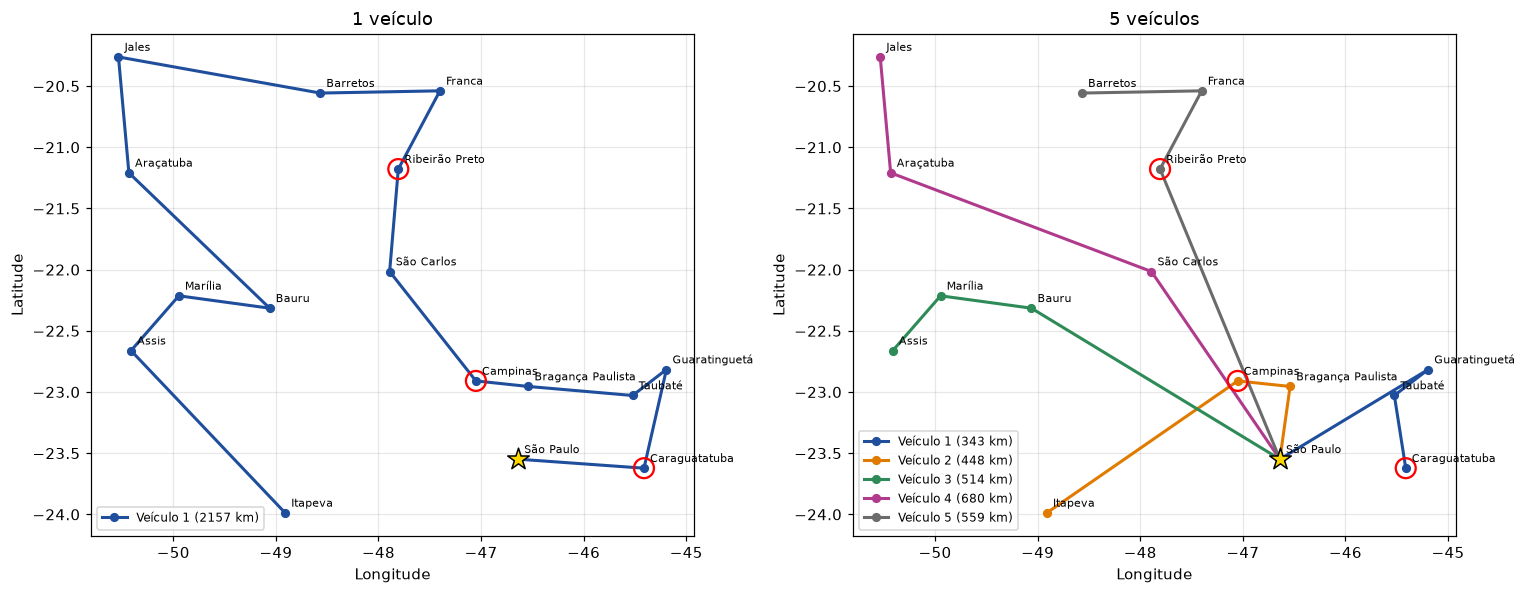

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
plot_routes(vehicle_runs[1], axes[0], title="1 veículo")
plot_routes(vehicle_runs[5], axes[1], title="5 veículos")
plt.tight_layout()
plt.show()

## 7. Comparação com outras abordagens de roteamento

Os números vêm de `backend/data/benchmark_results.json`, gerado por `python -m backend.benchmark` (10 sementes para os métodos aleatórios, 5 para o AG com os parâmetros do app web). Todos resolvem o mesmo problema: 15 cidades, 3 veículos, origem em São Paulo, rotas abertas e prazo de 17 h para as cidades prioritárias, com a **mesma divisão de cidades por veículo** do AG (5 por veículo). O OR-Tools (solver de roteamento do Google) é opcional e não está no `requirements.txt` (`pip install ortools`).

In [10]:
import json

results = json.loads((root / "backend" / "data" / "benchmark_results.json").read_text(encoding="utf-8"))
methods = results["methods"]

print(f"{'Método':<56}{'Média':>10}{'Melhor':>9}{'Pior':>9}{'Tempo':>8}{'Válidas':>9}")
for row in methods:
    d = row["distance_km"]
    print(f"{row['method']:<56}{d['mean']:>7.1f} km{d['min']:>6.0f} km{d['max']:>6.0f} km{row['seconds']:>6.1f}s{row['valid_runs']:>5}/{row['runs']}")

Método                                                       Média   Melhor     Pior   Tempo  Válidas
AG (população 200, vizinho mais próximo)                 2357.2 km  2326 km  2592 km   1.1s   10/10
AG (população 200, aleatória)                            2398.1 km  2326 km  2628 km   1.3s   10/10
AG (população 1000, parâmetros do app web)               2325.8 km  2326 km  2326 km  27.1s    5/5
Busca aleatória (25680 soluções)                         3140.8 km  2929 km  3507 km   3.3s   10/10
Vizinho mais próximo guloso (sem busca)                  2593.2 km  2593 km  2593 km   0.0s   10/10
Inserção mais barata (melhor de 200 construções)         2819.2 km  2708 km  2900 km   0.0s   10/10
OR-Tools (mesma divisão de cidades por veículo do AG)    2325.8 km  2326 km  2326 km  10.0s    1/1
OR-Tools (divisão livre das cidades)                     2011.1 km  2011 km  2011 km  10.0s    1/1


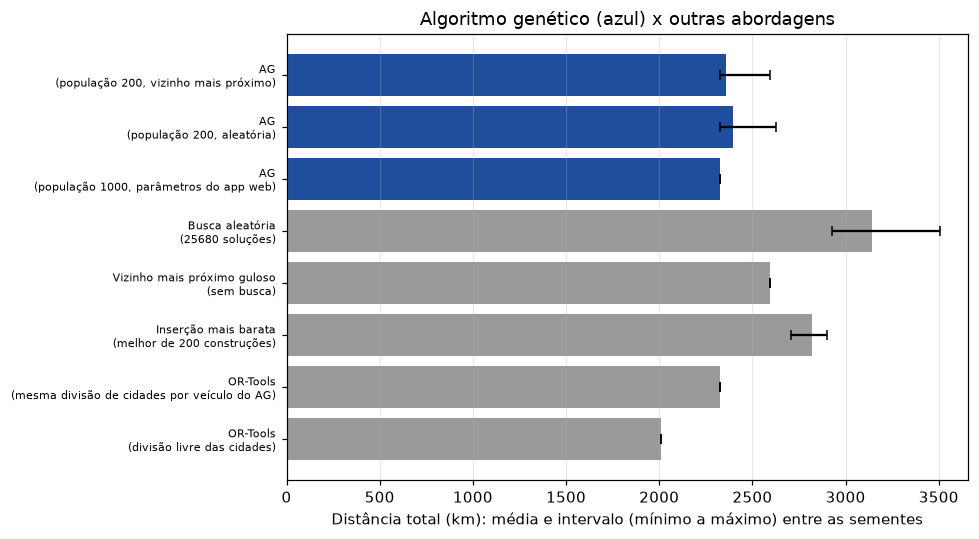

In [11]:
labels = [row["method"].replace(" (", "\n(") for row in methods]
means = [row["distance_km"]["mean"] for row in methods]
errors = [
    [row["distance_km"]["mean"] - row["distance_km"]["min"] for row in methods],
    [row["distance_km"]["max"] - row["distance_km"]["mean"] for row in methods],
]
colors = ["#1f4e9c" if row["method"].startswith("AG") else "#9a9a9a" for row in methods]

fig, ax = plt.subplots(figsize=(9, 5))
positions = range(len(methods))
ax.barh(positions, means, xerr=errors, color=colors, capsize=3)
ax.set_yticks(list(positions))
ax.set_yticklabels(labels, fontsize=7)
ax.invert_yaxis()
ax.set_xlim(0, max(row["distance_km"]["max"] for row in methods) + 150)
ax.set_xlabel("Distância total (km): média e intervalo (mínimo a máximo) entre as sementes")
ax.set_title("Algoritmo genético (azul) x outras abordagens")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### Instância pequena: o AG contra o ótimo exato

Com 8 cidades de destino e 2 veículos é possível testar **todas** as soluções (força bruta) e saber o ótimo de verdade. Com 15 cidades isso é inviável: só as ordens de visita já somam 15! (cerca de 1,3 trilhão).

In [12]:
small = results["small_instance"]
print(f"Cidades de destino: {small['cities']}, veículos: {small['vehicles']}")
print(f"Ótimo com a divisão do AG:   {small['balanced_optimum']['distance_km']:.1f} km "
      f"({small['balanced_solutions_tried']:,} soluções testadas em {small['balanced_seconds']:.2f}s)".replace(",", "."))
print(f"Ótimo com divisão livre:      {small['free_optimum']['distance_km']:.1f} km "
      f"({small['free_solutions_tried']:,} soluções testadas em {small['free_seconds']:.2f}s)".replace(",", "."))
print(f"AG: encontrou o ótimo em {small['ga_found_optimum']} de {len(small['ga_distances'])} sementes "
      f"(distância média {sum(small['ga_distances']) / len(small['ga_distances']):.1f} km)")

Cidades de destino: 8, veículos: 2
Ótimo com a divisão do AG:   1129.0 km (40.320 soluções testadas em 0.14s)
Ótimo com divisão livre:      1031.2 km (282.240 soluções testadas em 0.87s)
AG: encontrou o ótimo em 10 de 10 sementes (distância média 1129.0 km)


## Conclusões

Os números abaixo valem para estas execuções (16 cidades, sementes fixas); outras sementes ou instâncias maiores podem mudar o quadro.

- O algoritmo divide as cidades entre os veículos, ordena cada rota e respeita o prazo das prioridades: em todas as execuções acima a melhor solução cumpre as prioridades.
- **Estratégias de população:** nesta instância pequena, as três chegam a resultados parecidos e a melhor solução encontrada (2325,8 km) é a mesma. O vizinho mais próximo teve a menor média e a menor dispersão entre as sementes; a inserção mais barata teve a pior média por causa de uma semente que ficou longe das demais. No gráfico de convergência, as populações heurísticas já partem de soluções bem mais curtas (cerca de 2.600 a 2.900 km, contra 3.700 a 4.200 km da aleatória), mas a aleatória as alcança em cerca de 40 gerações, e o número total de gerações até estabilizar foi parecido. Diferenças maiores entre as estratégias provavelmente só apareceriam com mais cidades, o que não foi testado aqui.
- **Número de veículos:** a duração da solução cai a cada veículo adicionado (de 33h45 com 1 veículo para 10h10 com 5). A distância total não é monotônica, porque cada veículo parte de São Paulo e porque o algoritmo é estocástico e para ao estabilizar, sem garantia de ótimo global.
- **Comparação com outras abordagens:** o AG ficou bem à frente da busca aleatória com o mesmo número de soluções avaliadas e das construções gulosas, e com os parâmetros do app web chegou ao mesmo resultado que o OR-Tools com a mesma divisão de cidades. Na instância pequena, encontrou o ótimo exato em todas as sementes. Quando o OR-Tools pôde dividir as cidades livremente, a distância total caiu, mas com veículos muito desbalanceados (veja o relatório técnico).
- Para experimentar outras cidades, origem opcional, prioridades e a geração de instruções e relatórios por LLM, use a aplicação web (veja o README principal).